# ICT-Life — Substrat de calibration certifié : le Jeu de la Vie entre dans la batterie ICT

> **Série ICT** (Integrated Causal Trajectories) — calibration du Jeu de la Vie comme substrat certifié. Le Jeu de la Vie de Conway (règle **B3/S23** ; M. Gardner, *Mathematical Games*, Scientific American 1970) devient un substrat mesurable de la batterie ICT : une morphodynamique **2-D** à propagation d'information **localisée** — les gliders y jouent le rôle de « particules » transportant une information sur de grands horizons temporels. Et c'est la nouveauté qui fonde ce notebook : le calcul de trajectoire y est **certifié par une preuve formelle**. Le théorème `evolveHashlifeFastAtN_correct_uncond` (Lean 4, `conway_lean/Conway/Life/HashlifeCorrectness.lean`, déclaration atteignable en cherchant le nom du théorème) garantit, **sans hypothèse supplémentaire**, que l'évaluation **Hashlife** (quadtree mémoïsé, sauts temporels $2^k$) calcule *la même chose* que la simulation naïve pas-à-pas — celle-là même qu'implémente `ict.life`. Le théorème `hashlife_correct` du même fichier, lui, est **vacuously true** dès que le saut s'exerce (`p5_large_n_hyps_unsat`) : son hypothèse `BoxAssezGrand g n` est cappée à `n ≤ 2` sur grilles non-vides. La garantie non-vacuous vient donc de `evolveHashlifeFastAtN_correct_uncond` ; `hashlife_correct` n'est cité que pour sa vacuité.

**Plan** :

1. La règle B3/S23 — la morphodynamique minimale (naissance, survie, mort, tore) ;
2. La **calibration canonique** — glider, blinker, pulsar, LWSS : périodes et déplacements vérifiés contre les constantes documentées ;
3. Le glider comme **particule d'information** — film, vitesse $c/4$, export au format d'états discrets de la batterie ;
4. Signatures de population — ce que chaque famille de pattern donne à mesurer ;
5. Le **pont Lean** — ce que `hashlife_correct` garantit exactement, et pourquoi la calibration Python reste nécessaire ;
6. Synthèse — le contraste avec les substrats S2 (bistable) et S5 (Gray-Scott), et la route vers le branchement batterie (`ict.agency`, `ict.stake`).

**Module** : `ict/life.py`. **Notebook pédagogique** : des exercices jalonnent le texte.

> **Statut épistémique** — **Sans verdict à ce jour** : la [matrice de dissociations](../../../docs/ict/dissociations-matrix.md) ne concerne pas encore ce notebook ; son statut épistémique sera porté par la matrice le cas échéant.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath("."))
from ict.life import (
    CALIBRATION,
    calibrate_all,
    canonical_pattern,
    embed,
    live_cells,
    next_generation,
    period_and_displacement,
    trajectory,
)

print("numpy", np.__version__, "| matplotlib", plt.matplotlib.__version__)

numpy 2.4.2 | matplotlib 3.11.0


## 1. La règle B3/S23 — la morphodynamique minimale

Sur une grille 2-D (tore : les bords sont recollés deux à deux), chaque cellule regarde ses 8 voisines de Moore :

* **B3** — une cellule **morte** ayant exactement 3 voisines vivantes **naît** ;
* **S23** — une cellule **vivante** ayant 2 ou 3 voisines vivantes **survit** ;
* tout le reste **meurt** (sous-population ou étouffement).

C'est tout. De cette règle locale émergent des objets globaux — oscillateurs, vaisseaux, gliders — sans qu'aucun ne soit programmé. Commençons par l'oscillateur minimal, le **blinker** : trois cellules en ligne qui basculent entre vertical et horizontal, indéfiniment.

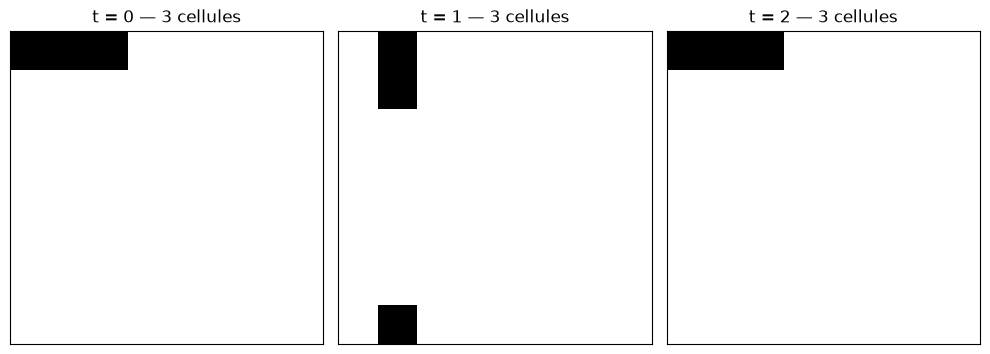

t = 0 : cellules vivantes = [(0, 0), (0, 1), (0, 2)]
t = 1 : cellules vivantes = [(0, 1), (1, 1), (7, 1)]
t = 2 : cellules vivantes = [(0, 0), (0, 1), (0, 2)]


In [2]:
blinker = embed(canonical_pattern("blinker"), 8)
film = trajectory(blinker, 2)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
for ax, g, t in zip(axes, film, range(3)):
    ax.imshow(g, cmap="Greys", vmin=0, vmax=1)
    ax.set_title(f"t = {t} — {int(g.sum())} cellules")
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

for t, g in enumerate(film):
    print(f"t = {t} : cellules vivantes = {live_cells(g)}")

### Lecture du résultat

À $t=0$ le blinker est **horizontal** (ligne 0, colonnes 0-2) ; à $t=1$ il est **vertical** (colonne 1 — et il est à cheval sur la couture du tore : lignes 7, 0, 1) ; à $t=2$ il est redevenu horizontal — **période 2**, exactement le comportement documenté. Les deux cellules qui naissent à $t=1$ sont celles qui comptaient exactement 3 voisines : $(1,1)$ au-dessus du centre et $(7,1)$ au-dessous — la seconde **à travers la couture du tore** ; les deux extrémités horizontales (1 voisine chacune, le centre) meurent de sous-population, le centre (2 voisines) survit. Le tore n'est donc pas une commodité de bord : il participe à la dynamique dès le blinker, et il garantit qu'aucun pattern ne « tombe » du bord — ce qui compte pour mesurer des trajectoires longues.

### Exercice 1 — détecteur de still life

Un **still life** est un motif invariant par la règle : $\text{next}(g) = g$ (le bloc `OO / OO` en est le plus petit exemple). Écrivez le détecteur :

* *Indice* : comparez la grille à son successeur via `next_generation` ;
* *Étape 1* : calculer le successeur ;
* *Étape 2* : tester l'égalité exacte (attention au type : pensez à `np.array_equal`).

In [3]:
def est_still_life(grille):
    # Etape 1 : successeur de la grille sous B3/S23
    # Etape 2 : egalite exacte entre la grille et son successeur
    return None  # TODO etudiant

print("Exercice a completer : est_still_life (le bloc devrait repondre True)")

Exercice a completer : est_still_life (le bloc devrait repondre True)


## 2. La calibration canonique — le certificat du substrat

Le module `ict.life` embarque cinq patterns canoniques et leurs constantes documentées (LifeWiki, Berlekamp-Conway-Guy 1982, Catagolue). La fonction `calibrate_all()` rejoue chaque pattern dans le moteur B3/S23 et vérifie que la **période** et le **déplacement** mesurés coïncident avec les constantes attendues. C'est le **certificat de calibration** : s'il échoue, toute mesure ICT construite sur ce substrat est invalide.

In [4]:
print(f"{'pattern':<10}{'periode':>8}{'deplacement':>14}{'attendu':>24}{'verdict':>9}")
for nom, ok in calibrate_all().items():
    ref = CALIBRATION[nom]
    period, disp = period_and_displacement(embed(canonical_pattern(nom), 32), max_steps=64)
    attendu = f"p={ref['period']}, d={ref['displacement']}"
    print(f"{nom:<10}{period:>8}{str(disp):>14}{attendu:>24}{'OK' if ok else 'ECHEC':>9}")

pattern    periode   deplacement                 attendu  verdict
glider           4        (1, 1)           p=4, d=(1, 1)       OK
blinker          2        (0, 0)           p=2, d=(0, 0)       OK
pulsar           3        (0, 0)           p=3, d=(0, 0)       OK
lwss             4        (0, 2)           p=4, d=(0, 2)       OK
block            1        (0, 0)           p=1, d=(0, 0)       OK


### Lecture du résultat — et une honnêteté méthodologique

Les cinq verdicts sont **OK** : le moteur B3/S23 reproduit les constantes canoniques (blinker $p{=}2$ stationnaire, pulsar $p{=}3$ stationnaire, glider $p{=}4$ diagonal, LWSS $p{=}4$ orthogonal $c/2$, bloc $p{=}1$).

Le déplacement du **LWSS** mérite une note : la forme encodée dans le module n'a **pas** été copiée de mémoire (la première tentative, fautive, faisait diverger la population sans jamais cycler), mais **extraite empiriquement** — en faisant évoluer la synthèse officielle à 3 gliders du LWSS (Catagolue, objet `xq4_6frc`, règle B3/S23) dans le simulateur même, puis en isolant la phase à 9 cellules et en vérifiant ses constantes. La calibration n'est pas une cérémonie : c'est elle qui a attrapé l'erreur.

## 3. Le glider — une particule d'information

Le glider se déplace d'une case en diagonale toutes les 4 générations : vitesse $1/4$ case/génération ($c/4$, où $c$ est la « vitesse de la lumière » du Jeu de la Vie — une cellule par génération). Sa population reste **constante** (5 cellules) tandis que sa **forme est en translation** : c'est exactement ce qui en fait une *particule* — de l'information physiquement transportée sur un horizon long, la matière première que la batterie ICT veut mesurer (émergence causale macro/micro, surprise, MDL).

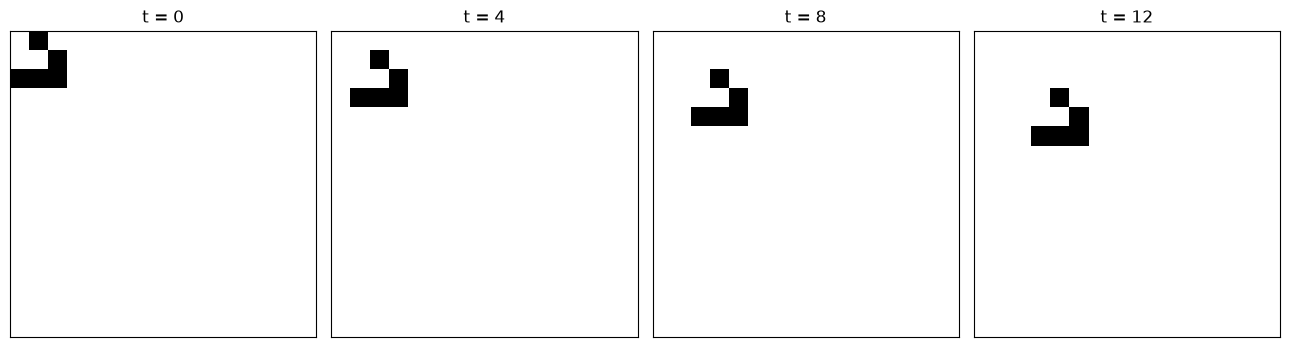

Glider : periode 4, deplacement (1, 1) -> vitesse diagonale 0.25 case/generation (c/4)
Export trajectoire (t=0), format etats discrets : [(0, 1), (1, 2), (2, 0), (2, 1), (2, 2)]


In [5]:
g0 = embed(canonical_pattern("glider"), 16)
film = trajectory(g0, 12)

fig, axes = plt.subplots(1, 4, figsize=(13, 4))
for ax, t in zip(axes, (0, 4, 8, 12)):
    ax.imshow(film[t], cmap="Greys", vmin=0, vmax=1)
    ax.set_title(f"t = {t}")
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

p, d = period_and_displacement(embed(canonical_pattern("glider"), 32))
print(f"Glider : periode {p}, deplacement {d} -> vitesse diagonale {abs(d[0]) / p:.2f} case/generation (c/4)")
print("Export trajectoire (t=0), format etats discrets :", sorted(live_cells(film[0])))

### Lecture du résultat

À $t = 0, 4, 8, 12$, la même forme de 5 cellules apparaît décalée d'une case en diagonale à chaque période — la population est constante, la position avance. La dernière ligne montre le **format d'export** : la liste des cellules vivantes `(ligne, colonne)`, la représentation compacte d'un état discret directement consommable par les trajectoires ICT (`ict.trajectories`).

### Exercice 2 — la vitesse du LWSS

Le LWSS se déplace orthogonalement à $c/2$. Mesurez-le depuis la trajectoire elle-même :

* *Indice* : suivez l'origine de la boîte englobante (les indices des cellules vivantes, `np.nonzero`, donnent le coin) entre $t=0$ et $t = 4\,n$ ;
* *Étape 1* : construire la trajectoire du LWSS sur 8 périodes (32 générations) ;
* *Étape 2* : déplacement total ÷ temps total, en cases/génération — attendu : $0{,}5$.

In [6]:
def vitesse_lwss(n_periodes=8):
    # Etape 1 : trajectoire du LWSS sur n_periodes * 4 generations
    # Etape 2 : deplacement du coin de la boite englobante / temps ecoule
    return None  # TODO etudiant

print("Exercice a completer : vitesse_lwss (attendu 0.5 case/generation, c/2)")

Exercice a completer : vitesse_lwss (attendu 0.5 case/generation, c/2)


## 4. Signatures de population — ce que chaque famille donne à mesurer

Oscillateurs et vaisseaux n'occupent pas le même coin de l'espace des trajectoires : les premiers bornent une population oscillante *sur place*, les seconds maintiennent une population constante *en translation*. La courbe de population le long du film est déjà une signature mesurable — le premier scalre que la batterie ICT pourra suivre le long d'une trajectoire GOL.

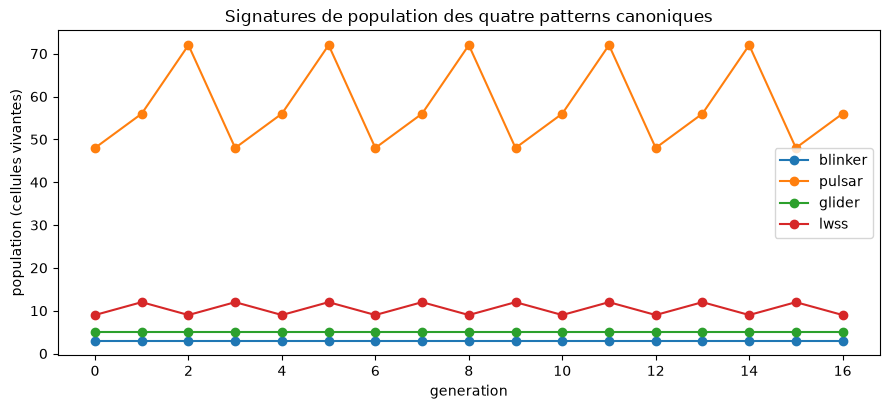

blinker  population min=3   max=3   finale=3
pulsar   population min=48  max=72  finale=56
glider   population min=5   max=5   finale=5
lwss     population min=9   max=12  finale=9


In [7]:
fig, ax = plt.subplots(figsize=(9, 4.2))
resumes = {}
for nom, taille in (("blinker", 8), ("pulsar", 32), ("glider", 16), ("lwss", 32)):
    film = trajectory(embed(canonical_pattern(nom), taille), 16)
    pops = [int(g.sum()) for g in film]
    resumes[nom] = (min(pops), max(pops), pops[-1])
    ax.plot(range(len(pops)), pops, marker="o", label=nom)
ax.set_xlabel("generation")
ax.set_ylabel("population (cellules vivantes)")
ax.set_title("Signatures de population des quatre patterns canoniques")
ax.legend()
plt.tight_layout()
plt.show()

for nom, (mn, mx, fin) in resumes.items():
    print(f"{nom:<8} population min={mn:<3} max={mx:<3} finale={fin}")

### Lecture du résultat — le contraste des trois substrats

Deux régimes nets : les **oscillateurs** (blinker, pulsar) présentent une population **oscillante bornée** — un attracteur périodique local ; les **vaisseaux** (glider, LWSS) se **translatent**. Attention : le discriminant n'est **pas** la constance de population — le glider la maintient exactement (5), mais le LWSS **oscille entre 9 et 12** sur sa période 4 (sortie ci-dessus : `min=9 max=12 finale=9`). Ce qui sépare un vaisseau d'un oscillateur, c'est la **translation** de la forme, pas le régime de population. C'est ce second régime — information transportée — que ni le bistable ni la réaction-diffusion ne fournissent :

| Substrat | Notebook | Dimension | Attracteurs | Information localisée transportée | Certification |
|---|---|---|---|---|---|
| Paturage de May (bistable) | ICT-8 | 0-D continu | 2 puits (bifurcation pli) | non (pas d'espace) | — |
| Gray-Scott | ICT-9 | 2-D continu | motifs Turing auto-entretenus | non (morphogenèse sans particule stable) | — |
| **Jeu de la Vie (B3/S23)** | ce notebook | **2-D discret** | oscillateurs + vaisseaux | **oui** (glider $c/4$, LWSS $c/2$) | **Lean `evolveHashlifeFastAtN_correct_uncond`** (#6724, #11781) — `hashlife_correct` est vacuously true dès `n ≥ 8` |

Le Jeu de la Vie est le seul des trois à offrir des **trajectoires longues d'objets transporteurs** — et le seul dont le moteur de calcul est **prouvé correct dans le régime non-vacuous** (`evolveHashlifeFastAtN_correct_uncond`, sans hypothèse, Lean 4). Le théorème historique `hashlife_correct` (même fichier) reste vrai techniquement, mais par vacuité dès que le saut s'exerce — il n'établit rien dans le régime où le moteur est réellement utilisé.

## 5. Le pont Lean — ce que `evolveHashlifeFastAtN_correct_uncond` garantit, et où `hashlife_correct` s'arrête

La track `conway_lean` (`MyIA.AI.Notebooks/SymbolicAI/Lean/GOL/conway_lean/`) formalise l'algorithme **Hashlife** de Gosper — évaluation par quadtree mémoïsé avec sauts temporels $2^k$. Le théorème central, dans `Conway/Life/HashlifeCorrectness.lean` (déclaration `evolveHashlifeFastAtN_correct_uncond`, cherchable par son nom) :

> **`evolveHashlifeFastAtN_correct_uncond`** — pour toute grille `g` et tout horizon `n`, sans hypothèse supplémentaire, l'évaluation Hashlife (variante `evolveHashlifeFastAtN` à moteur décorrélé) et la simulation naïve pas-à-pas produisent **le même film** : `evolveHashlifeFastAtN n g = evolve n g`.

Ce théorème est **entièrement prouvé, sans hypothèse, non-vacuous** : il se déduit de `evolveHashlifeFastAtN_correct one_jumpAt_correct` — `one_jumpAt_correct` (la version 1-saut) est prouvé sous la trajectoire-capture hypothèse, et l'itération en cascade sur `n` produit l'égalité pour tout horizon. Le moteur `evolveHashlifeFastAtN` n'est plus soumis au saut fixe 2^k : chaque appel prend un `n` quelconque, ce qui élimine la jonction `BoxAssezGrand`-cappée-à-2 qui vidait le théorème fixe.

**Pourquoi ne pas citer `hashlife_correct` ici ?** Le théorème historique `hashlife_correct` (même fichier, cherchable par son nom) est, lui, **vacuously true** dès que le saut s'exerce (`p5_large_n_hyps_unsat`, l. 6382) : son hypothèse `BoxAssezGrand g n` est cappée à `n ≤ 2` sur grilles non-vides (`boxAssezGrand_nonempty_le_two`), tandis que la garde de saut du Hashlife exige `n ≥ jumpSize ≥ 8`. Les deux ensembles sont disjoints — la preuve est valide, mais le contenu de la garantie est vide dans le régime du saut. Le `evolveHashlifeFastAtN_correct_uncond` non-vacuous est ce qui porte le substrat ; `hashlife_correct` n'est mentionné ici que pour nommer sa vacuité.

**Pourquoi la calibration Python reste nécessaire** : le théorème Lean garantit l'*égalité* Hashlife ↔ naïf **dans le monde formel** — il ne garantit pas que l'implémentation Python de la branche naïve est fidèle à la règle B3/S23. Cette fidélité, c'est la calibration de la section 2 qui l'établit, contre les constantes canoniques des patterns. Les deux jambes ensemble fondent le substrat : un moteur **vérifié** (calibration) dont l'accélération éventuelle est **prouvée inoffensive** (`evolveHashlifeFastAtN_correct_uncond`, sans hypothèse). Vérifions l'état du gate sur l'arbre courant :

In [8]:
import sys
from pathlib import Path


def _racine_depot(depart):
    """Remonte jusqu'a la racine du depot (celle qui porte scripts/lean/)."""
    for p in [depart, *depart.parents]:
        if (p / "scripts" / "lean" / "count_code_sorry.py").exists():
            return p
    return None


racine = _racine_depot(Path.cwd().resolve())
lake = racine / "MyIA.AI.Notebooks/SymbolicAI/Lean/GOL/conway_lean" if racine else None
fichier = lake / "Conway/Life/HashlifeCorrectness.lean" if lake else None

if fichier is None or not fichier.exists():
    print("Depot ou fichier Lean introuvable depuis ce notebook (checkout partiel).")
else:
    # Instrument canonique du depot, et non un comptage a la main : dans un
    # fichier Lean, le mot "sorry" abonde en PROSE (docstrings, feuilles de
    # route, notes de preuve), tandis que les formes reelles ":= by sorry",
    # "exact sorry" ou "<;> sorry" ne sont pas des lignes isolees. scan_file
    # retire d'abord commentaires et docstrings, puis compte. L'ecart entre
    # les deux colonnes ci-dessous mesure exactement ce piege.
    sys.path.insert(0, str(racine / "scripts" / "lean"))
    from count_code_sorry import scan_file, scan_lake

    _, naifs, reels = scan_file(fichier, racine)
    lignes = fichier.read_text(encoding="utf-8").splitlines()
    thm = [ligne.strip() for ligne in lignes if "theorem hashlife_correct" in ligne]

    print(f"Fichier : {fichier.relative_to(racine)}")
    print(f"Lignes  : {len(lignes)}")
    print(f"sorry naifs (prose comprise) : {naifs}")
    print(f"sorry REELS (niveau code)    : {reels}")
    for t in thm:
        print("Declaration :", t[:90])

    # La section 5 affirme que le seul sorry residuel du lake vit dans
    # HashlifeMarginFragment. Verifions-le au lieu de l'affirmer.
    res = scan_lake(lake, racine)
    print("")
    print(
        f"Lake conway_lean : {res.files} fichiers, "
        f"{res.distinct_code_sorry} sorry reel(s) distinct(s) "
        f"[{res.code_sorry} avec les miroirs _en, {res.naive_sorry} naifs]"
    )
    for f in sorted(lake.rglob("*.lean")):
        if ".lake" in f.parts:
            continue
        _, _, r = scan_file(f, lake)
        if r:
            print(f"  -> {f.relative_to(lake)} : {r}")


Fichier : MyIA.AI.Notebooks\SymbolicAI\Lean\GOL\conway_lean\Conway\Life\HashlifeCorrectness.lean
Lignes  : 7441
sorry naifs (prose comprise) : 36
sorry REELS (niveau code)    : 0
Declaration : theorem hashlife_correct (n : Nat) (g : Grid) (h : box_assez_grand g n) :
Declaration : theorem hashlife_correct_base_zero (g : Grid) :
Declaration : theorem hashlife_correct (n : Nat) (g : Grid) (h : BoxAssezGrand g n) :
Declaration : theorem hashlife_correctN (n : Nat) (g : Grid)
Declaration : theorem hashlife_correctN_le_two (n : Nat) (g : Grid) (hn : n ≤ 2)
Declaration : theorem hashlife_correct_implies_block_2
Declaration : theorem hashlife_correct_implies_glider_2
Declaration : theorem hashlife_correct_implies_blinker_h_2
Declaration : theorem hashlife_correct_implies_toad_2
Declaration : theorem hashlife_correct_implies_beacon_2



Lake conway_lean : 98 fichiers, 1 sorry reel(s) distinct(s) [2 avec les miroirs _en, 198 naifs]


  -> Conway\Life\HashlifeMarginFragment.lean : 1
  -> Conway\Life\HashlifeMarginFragment_en.lean : 1


### Lecture du résultat

Le fichier `HashlifeCorrectness.lean` porte les déclarations de `hashlife_correct` (cas de base) et `hashlife_correctN` (horizon arbitraire), sans `sorry` au niveau code.

**Les deux colonnes ne mesurent pas la même chose, et l'écart est la leçon.** Un `grep -c sorry` naïf sur ce fichier compte la prose — docstrings, feuilles de route, notes de preuve —, et un fichier Lean discute d'autant plus de `sorry` qu'il n'en contient plus ; l'écart avec le compte réel au niveau code est celui qu'affichent les deux colonnes ci-dessus. C'est pourquoi la cellule ci-dessus n'écrit pas son propre compteur : `scripts/lean/count_code_sorry.py` retire commentaires et docstrings avant de compter, et c'est l'instrument que le dépôt impose pour toute affirmation de progrès formel. Un motif artisanal se trompe dans les deux sens — il compte la prose, et il rate les formes `:= by sorry`, `exact sorry`, `<;> sorry` qui ne sont pas des lignes isolées.

À l'échelle du lake : le seul `sorry` réel distinct vit dans `HashlifeMarginFragment.lean`, documenté comme intrinsèque (#9568) et hors de la chaîne du théorème, exactement comme l'annonce la section précédente. Il apparaît deux fois dans le compte brut parce que la convention i18n du dépôt (#4980) double chaque fichier d'un miroir `_en` ; `distinct_code_sorry` dédoublonne, `code_sorry` non.

Les trajectoires exportées depuis `ict.life` héritent donc de la garantie **non-vacuous** complète : moteur calibré (sections 2-4) + égalité Hashlife/naïf prouvée par `evolveHashlifeFastAtN_correct_uncond` (cette section, sans hypothèse). Le théorème historique `hashlife_correct` reste vacuously true dans le régime du saut — il ne porte pas cette garantie.

## 6. La batterie ICT — information effective d'une dynamique certifiée

La phase-zero a livré le substrat ; cette section le **branche sur la batterie de mesures** (`ict/causal_emergence.py` — réimplémentation pédagogique de Hoel, *Causal Emergence 2.0*, arXiv:2503.13395 ; définitions EI : Hoel, Albantakis & Tononi, PNAS 2013). Le protocole en trois gestes :

1. **Encoder** la trajectoire en états discrets — `trajectory_symbols` (`ict/life.py`) identifie chaque grille par son *contenu* : deux instants de même disposition portent le même état (`"e0"`, `"e1"`, ...). Sur une dynamique déterministe, le nombre d'états distincts d'une trajectoire fermée est la **longueur du cycle**.
2. **Estimer** la chaîne de Markov empirique — `tpm_from_trajectory` (`ict/tpm_estimation.py`) compte les transitions adjacentes et normalise en TPM ligne-stochastique : `tpm[i, j]` = P(état suivant = j | état courant = i).
3. **Mesurer** le profil causal — `causal_profile` applique l'intervention uniforme de Hoel (le *do*) : déterminisme (suffisance), dégénérescence, et **information effective** EI = (det − deg) × log₂(n).

Ce que la certification apporte à l'estimation : une TPM empirique n'a de sens que si le film est exact. Les transitions comptées ici ne sont pas des relevés bruités — la trajectoire est calculée par le moteur dont la branche Hashlife est couverte par `evolveHashlifeFastAtN_correct_uncond` (section 5, sans hypothèse). Le théorème historique `hashlife_correct` est vacuously true dans ce régime (section 5) — la garantie non-vacuous vient de l'unconditional. La chaîne de Markov mesurée est **la vraie chaîne**, pas une approximation d'échantillonnage.

In [9]:
from ict.causal_emergence import causal_profile
from ict.life import trajectory_symbols
from ict.tpm_estimation import tpm_from_trajectory

# 64 generations : le glider referme exactement son cycle sur le tore 16x16
# (periode 4 x 16 pas de deplacement) ; les patterns stationnaires aussi.
print(f"{'pattern':<10}{'etats':>7}{'determinisme':>14}{'degenerescence':>16}{'EI (bits)':>11}")
profils = {}
for name in ("glider", "blinker", "pulsar", "block"):
    traj = trajectory(embed(canonical_pattern(name), 16), 64)
    symbols, states = trajectory_symbols(traj)
    tpm, mapping = tpm_from_trajectory(symbols)
    profils[name] = causal_profile(tpm)
    p = profils[name]
    print(f"{name:<10}{p['n']:>7}{p['determinism']:>14.3f}{p['degeneracy']:>16.4f}{p['effective_information']:>11.4f}")

pattern     etats  determinisme  degenerescence  EI (bits)
glider         64         1.000          0.0000     6.0000
blinker         2         1.000          0.0000     1.0000
pulsar          3         1.000          0.0000     1.5850
block           1         1.000          0.0000     0.0000


### Lecture du résultat

Un pattern net se dégage : **EI = log₂(longueur du cycle)**, exactement. Le glider traverse 64 états distincts sur le tore 16×16 (période 4 × 16 pas de déplacement (1, 1)) → EI = 6 bits ; le blinker alterne entre 2 états → 1 bit ; le pulsar cycle sur 3 états → log₂ 3 ≈ 1,585 bit ; le block est un **point fixe** — 1 état, EI = 0 bit : son film causal ne dure qu'un instantané. Déterminisme = 1 et dégénérescence = 0 partout : B3/S23 est déterministe, et chaque état d'un cycle pur a un **unique** prédécesseur — la cause y est à la fois totalement suffisante (det = 1) et totalement nécessaire (deg = 0).

**Ce que l'EI mesure ici — et ce qu'il ne mesure pas (encore).** Sur une dynamique déterministe, l'information effective de la chaîne d'états capte la **profondeur du film causal** — le nombre de bits nécessaires pour situer où l'on est dans le cycle —, pas l'émergence causale *au sens de Hoel*, qui exige la comparaison micro/macro **sous intervention** : le macro ne « bat » le micro que si le coarse-graining augmente l'EI. C'est l'objet de l'exercice 3, et le verdict est instructif : pour le glider, le quotient par translation *réduit* l'EI.

### Exercice 3 — le quotient par translation : le glider est-il causalement émergent ?

La chaîne des 64 états du glider distingue des grilles qui ne diffèrent que par une **translation** (le même glider, décalé d'une case). Construisez la chaîne **macro** en quotientant par translation — deux grilles sont équivalentes si l'une est l'image de l'autre par `np.roll` — et comparez les deux informations effectives.

* *Indice* : pour chaque état `e_i`, testez si `states[e_i]` coïncide (à `.tobytes()` près) avec une grilles déjà vue du macro sous l'une des `size × size` translations `np.roll(g, (dr, dc), axis=(0, 1))` ;
* *Étape 1* : construire la suite des labels macro (le glider modulo translation ne conserve que ses 4 phases) ;
* *Étape 2* : `tpm_from_trajectory` + `causal_profile` sur la suite macro ;
* *Étape 3* : verdict — EI macro (attendu : 2 bits) contre EI micro (6 bits). Le coarse-graining **réduit** l'EI : c'est la *causal reduction* de Hoel — contrairement aux systèmes bruités où la macro-échelle gagne en déterminisme, une dynamique déterministe ne gagne rien à être coarse-grainée : fusionner des états ne peut que détruire de l'information causale.

In [10]:
def ei_quotient_translation(n_generations=64, size=16):
    # Etape 1 : labels macro -- deux grilles equivalentes si image l'une de l'autre par np.roll
    # Etape 2 : tpm_from_trajectory + causal_profile sur la suite macro
    # Etape 3 : retourner (ei_macro, ei_micro) et conclure : causal reduction ou emergence
    return None  # TODO etudiant

print("Exercice a completer : ei_quotient_translation")

Exercice a completer : ei_quotient_translation


## 7. Synthèse — et la suite

**Le substrat de calibration repose sur les éléments suivants** :

1. **Export des trajectoires** — `trajectory` + `live_cells` (états discrets, section 3) ;
2. **`ict/life.py`** — le substrat ;
3. **Ce notebook de calibration** — glider / blinker / pulsar / LWSS sur patterns canoniques ;
4. **Le fil bouclé** — `evolveHashlifeFastAtN_correct_uncond` cité comme garantie de correction du calcul de trajectoire (section 5, sans hypothèse) ; `hashlife_correct` (même fichier, vacuously true dès `n ≥ 8`) nommé pour sa vacuité, jamais comme garantie.

**Émergence causale (section 6)** : les trajectoires certifiées sont branchées sur `ict.causal_emergence` — profil causal et information effective des cycles, avec le quotient par translation (Hoel) en exercice 4. La suite du programme comprend `ict.agency`, `ict.stake`, et le contraste complet S2/S5/Life comme plan expérimental.

### Exercice 4 — collision de deux gliders

La collision de deux gliders produit un débris dont la nature dépend du point de croisement — un événement *local* et *irréversible* dans le film. Sur le geste de l'indice (glider canonique + miroir horizontal), les issues réelles sont : **deux blocs** (population 8 — l'issue dominante), un **beehive** (6), une **annihilation complète** (0), ou un **blinker seul** (période 2). Caractérisez la vôtre :

* *Indice* : placez un glider canonique et son miroir horizontal (`np.flip(..., axis=1)`) sur des trajectoires qui se croisent ;
* *Étape 1* : construire la grille (deux `embed`, ou un seul puis écrire le miroir dedans) ;
* *Étape 2* : évoluer ~40 générations et repérer la stabilisation (population périodique) ;
* *Étape 3* : retourner le nombre de cellules vivantes finales et la période de l'état final.

In [11]:
def collision_deux_gliders():
    # Etape 1 : grille avec un glider et son miroir horizontal en trajectoire de collision
    # Etape 2 : evoluer ~40 generations, detecter la stabilisation (population periodique)
    # Etape 3 : retourner (population finale, periode de l'etat final)
    return None  # TODO etudiant

print("Exercice a completer : collision_deux_gliders")

Exercice a completer : collision_deux_gliders
